# 02 · Análisis exploratorio descriptivo (2015–2019)
**Grupo 2 · Estadística Bayesiana · Entrega final**  
Jean Paul Rojas Rojas · Daniel Estiven Pacheco Villagrande · Diego Andrés Cascante Camacho

**Qué hace.** Sección 3 del notebook EDA original (año, hora, localidad, celdas, día y tipo de lugar, V de Cramér, conteo frente a proporción, tablas) y las cuatro figuras exploratorias del informe final (Figuras 1 a 4).

**Entradas.** `datos/siniestros_limpios.csv` (de 01).

**Salidas.** `salidas/eda_original/figs/fig1, fig2, fig4` y `tablas/tab_*.tex`; `salidas/figuras/eda_hora.png, eda_localidad.png, eda_celdas.png, eda_anio.png`; `salidas/resultados/02_eda.json`.

*Respaldo por etapas: el notebook principal es `../Grupo2_Bayesiana_completo.ipynb`, que reúne estas ocho etapas.* Orden de ejecución y trazabilidad completa: `../README.md`.

In [1]:
# Configuración: funciona en Google Colab y en un computador
# En Colab: suba la carpeta "notebooks" a su Drive. Si el buscador automático no la encuentra,
# escriba su ruta en BASE_COLAB, p. ej. '/content/drive/MyDrive/Grupo2_EntregaFinal_Bayesiana/notebooks'
BASE_COLAB = ''
import os, sys, glob
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not BASE_COLAB:
        cand = glob.glob('/content/drive/MyDrive/**/notebooks/comun.py', recursive=True)
        assert cand, 'No encontré la carpeta notebooks en su Drive: escriba su ruta en BASE_COLAB'
        BASE_COLAB = os.path.dirname(cand[0])
    BASE = Path(BASE_COLAB)
else:
    # el notebook puede estar en notebooks/ o en notebooks/por_etapas/
    BASE = Path.cwd() if (Path.cwd() / 'comun.py').exists() else Path.cwd().parent
os.chdir(BASE)
sys.path.insert(0, str(BASE))
import numpy, pandas, scipy, matplotlib
print('Carpeta:', BASE)
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Carpeta: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks
Python 3.12.10 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.10.7


In [2]:
# Encabezado del notebook EDA original (sección 0), sin la parte de rutas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', font_scale=0.95)
SEMILLA = 2026          # semilla del EDA original (Primera Entrega); el modelo final usa 20261109
rng = np.random.default_rng(SEMILLA)

In [3]:
# Datos limpios producidos por 01 (no se vuelve a leer el Excel)
from comun import *
sin = pd.read_csv(ruta_datos('siniestros_limpios.csv'), parse_dates=['fecha'])
# como en el notebook original: categorías completas (20 localidades x 4 franjas = 80 celdas, con Sumapaz vacías)
sin['localidad'] = pd.Categorical(sin.localidad, categories=LOCS)
sin['franja'] = pd.Categorical(sin.franja, categories=FRANJAS, ordered=True)
sin['franja3h'] = pd.Categorical(sin.franja3h, categories=FR3, ordered=True)
base =sin[sin.anio <= 2019].copy()
ajuste_df = base[base.periodo == 'Ajuste 2015-2017']
CARPETA_TRABAJADOS = str(DATOS)
(SALIDAS / 'eda_original' / 'figs').mkdir(parents=True, exist_ok=True)
(SALIDAS / 'eda_original' / 'tablas').mkdir(parents=True, exist_ok=True)
os.chdir(SALIDAS / 'eda_original')     # las figuras y tablas del EDA original quedan aquí
print(len(sin), 'siniestros;', len(base), 'en 2015-2019;', len(ajuste_df), 'en 2015-2017')

196152 siniestros; 173443 en 2015-2019; 101500 en 2015-2017


## 3. Análisis exploratorio descriptivo (2015–2019)
Esta sección **describe** la ciudad en el periodo base (objetivo específico 1). No se usa para fijar priors.

### 3.1 Panorama general

In [4]:
display(pd.Series({'Siniestros 2015-2019': len(base), 'Graves': base.grave.sum(), '% graves': base.grave.mean() * 100,
                   'Con al menos un muerto': base.con_muertos.sum(), '% con muertos': base.con_muertos.mean() * 100}).to_frame('valor'))

,valor
Siniestros 2015-2019,"173,443.000"
Graves,"59,303.000"
% graves,34.192
Con al menos un muerto,"2,626.000"
% con muertos,1.514


### 3.2 ¿La gravedad cambia entre años?

In [5]:
por_anio = sin.groupby('anio').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
por_anio['pct_graves'] *= 100
display(por_anio)

,siniestros,graves,pct_graves
anio,,,
2015,31341,11267,35.950
2016,34988,11145,31.854
2017,35171,10919,31.045
2018,36953,13109,35.475
2019,34990,12863,36.762
2020,22709,8930,39.324


**Qué vemos.** El porcentaje de graves sube y baja entre años (cerca de 31 % en 2017, casi 37 % en 2019). En 2020 hay muchos menos siniestros pero más proporción de graves (39 %).

**Decisión.** 2020 queda aparte. Como el nivel cambia entre años, el periodo de ajuste es menos grave en promedio que el de prueba; por eso el año entra al modelo (M2) en la entrega final.

### 3.3 ¿A qué hora son más graves?

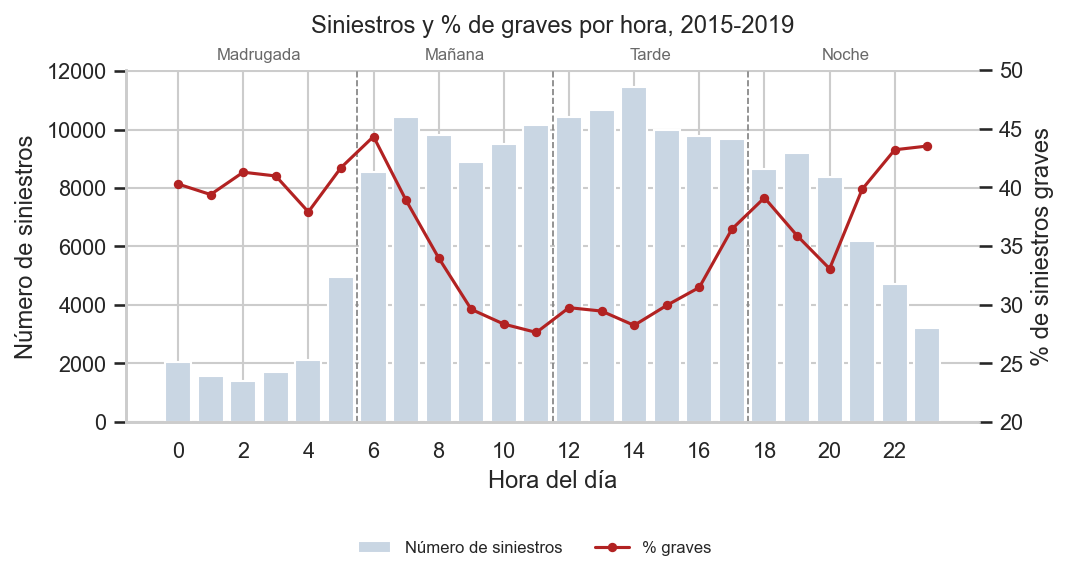

,siniestros,graves,pct_graves,pct_muertos
franja,,,,
Madrugada (0-6),13749,5569,40.505,3.455
Mañana (6-12),57391,19326,33.674,1.218
Tarde (12-18),61991,19066,30.756,1.079
Noche (18-24),40312,15342,38.058,1.942


In [6]:
h = base.groupby('hora').agg(siniestros=('grave', 'size'), pct=('grave', 'mean'))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.set_axisbelow(True)
ax.bar(h.index, h.siniestros, color='#c9d6e3', label='Número de siniestros', zorder=2)
ax.set_xlabel('Hora del día'); ax.set_ylabel('Número de siniestros'); ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(h.index, h.pct * 100, color='#b22222', marker='o', ms=3.5, label='% graves', zorder=3)
ax2.set_ylabel('% de siniestros graves'); ax2.set_ylim(20, 50)
for corte in [6, 12, 18]:
    ax.axvline(corte - 0.5, color='grey', ls='--', lw=0.8, zorder=1)
for x, t in zip([2.5, 8.5, 14.5, 20.5], ['Madrugada', 'Mañana', 'Tarde', 'Noche']):
    ax.text(x, 1.02, t, transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=8, color='dimgrey')
ax.set_title('Siniestros y % de graves por hora, 2015-2019', pad=18)
plt.tight_layout(); fig.subplots_adjust(bottom=0.25)
fig.legend(loc='lower center', ncol=2, fontsize=8, frameon=False)
plt.savefig('figs/fig1_hora.pdf'); plt.show()

franja_tab = base.groupby('franja', observed=True).agg(siniestros=('grave', 'size'), graves=('grave', 'sum'),
                                                       pct_graves=('grave', 'mean'), pct_muertos=('con_muertos', 'mean'))
franja_tab[['pct_graves', 'pct_muertos']] *= 100
display(franja_tab)

**Qué vemos.** Forma de "U": de día hay muchos siniestros pero menos graves (28–30 % entre las 9 y las 16); en la madrugada y al final de la noche hay menos siniestros pero cerca de 40 % o más son graves. El bloque "mañana" mezcla dos momentos distintos (6–9 y 9–12), por eso se probarán franjas de 3 horas.

### 3.4 ¿Las localidades con más siniestros son las más graves?

C:\Users\dddan\AppData\Local\Temp\ipykernel_28992\2337651253.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  loc = base.groupby('localidad').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))


Spearman entre número de siniestros y % graves (19 localidades): -0.63


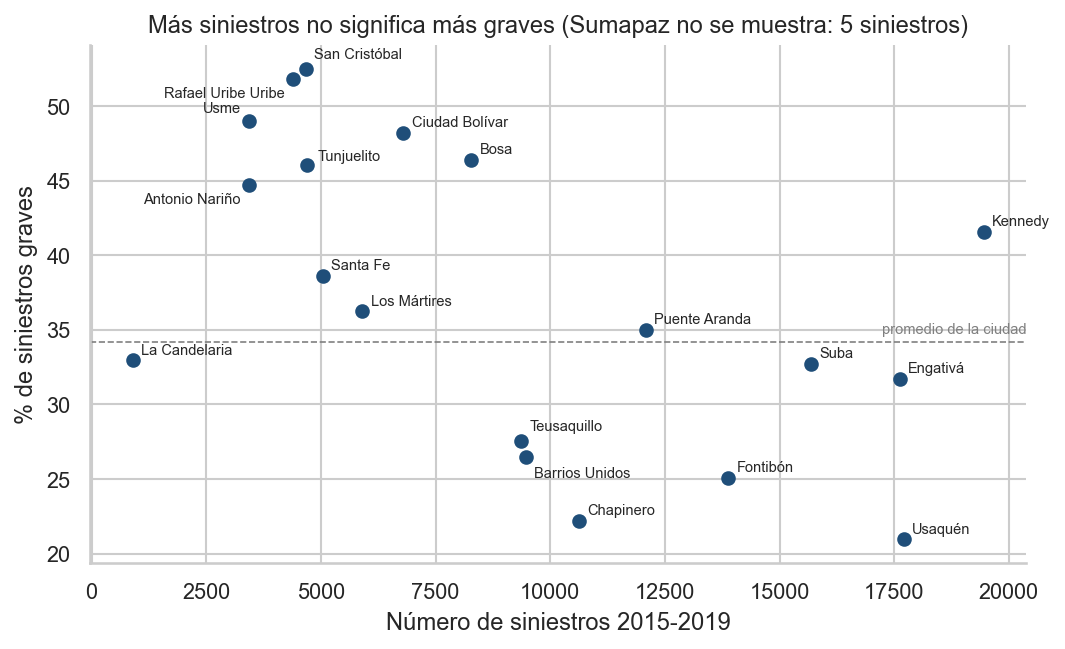

,siniestros,graves,pct_graves
localidad,,,
Sumapaz,5,3,60.000
San Cristóbal,4674,2455,52.525
Rafael Uribe Uribe,4389,2274,51.811
Usme,3429,1680,48.994
Ciudad Bolívar,6798,3277,48.205
Bosa,8274,3840,46.410
Tunjuelito,4701,2166,46.075
Antonio Nariño,3431,1535,44.739
Kennedy,19452,8087,41.574


In [7]:
loc = base.groupby('localidad').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
loc['pct_graves'] *= 100
loc = loc.sort_values('pct_graves', ascending=False)
sin_sumapaz = loc.drop('Sumapaz')
rho = stats.spearmanr(sin_sumapaz.siniestros, sin_sumapaz.pct_graves).statistic
print(f'Spearman entre número de siniestros y % graves (19 localidades): {rho:.2f}')

desplaz = {'San Cristóbal': (4, 5, 'left'), 'Rafael Uribe Uribe': (-4, -9, 'right'), 'Antonio Nariño': (-4, -9, 'right'),
           'Tunjuelito': (5, 2, 'left'), 'Teusaquillo': (4, 5, 'left'), 'Barrios Unidos': (4, -10, 'left'), 'Usme': (-4, 4, 'right')}
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.scatter(sin_sumapaz.siniestros, sin_sumapaz.pct_graves, color='#1f4e79', zorder=3)
for nombre, fila in sin_sumapaz.iterrows():
    dx, dy, ha = desplaz.get(nombre, (4, 3, 'left'))
    ax.annotate(nombre, (fila.siniestros, fila.pct_graves), fontsize=7, xytext=(dx, dy), textcoords='offset points', ha=ha)
ax.axhline(base.grave.mean() * 100, color='grey', ls='--', lw=0.8)
ax.text(ax.get_xlim()[1], base.grave.mean() * 100 + 0.6, 'promedio de la ciudad', ha='right', fontsize=7, color='grey')
ax.set_xlabel('Número de siniestros 2015-2019'); ax.set_ylabel('% de siniestros graves')
ax.set_title('Más siniestros no significa más graves (Sumapaz no se muestra: 5 siniestros)')
plt.tight_layout(); plt.savefig('figs/fig2_localidades.pdf'); plt.show()
display(loc)

**Qué vemos.** Las localidades con más siniestros (Usaquén, Engativá, Suba) tienen menos proporción de graves, y las del sur (San Cristóbal, Rafael Uribe Uribe, Usme, Ciudad Bolívar) tienen cerca de la mitad o más. Kennedy es la excepción: muchos siniestros y proporción alta.

**Cuidado al leerlo.** Dos explicaciones posibles que los datos no separan: (1) allí los siniestros son más graves, o (2) allí se reportan menos los choques leves, lo que infla el porcentaje (supuesto S1). Por eso se hará la prueba "solo con muertos" y el resultado se presenta como "severidad en lo registrado".

### 3.5 Las celdas localidad × franja

In [8]:
celdas = base.groupby(['localidad', 'franja'], observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()
assert len(celdas) == 80 and celdas.n.sum() == len(base), 'Se perdieron siniestros al agrupar'
celdas['prop'] = celdas.graves / celdas.n.replace(0, np.nan)
print('Mediana de siniestros por celda:', int(celdas.n.median()))
print('Celdas con menos de 30:', (celdas.n < 30).sum(), '| con menos de 100:', (celdas.n < 100).sum())
display(celdas[celdas.n < 100])

Mediana de siniestros por celda: 1517
Celdas con menos de 30: 4 | con menos de 100: 5


,localidad,franja,n,graves,prop
32,La Candelaria,Madrugada (0-6),51,24,0.471
60,Sumapaz,Madrugada (0-6),0,0,NaN
61,Sumapaz,Mañana (6-12),1,1,1.000
62,Sumapaz,Tarde (12-18),2,1,0.500
63,Sumapaz,Noche (18-24),2,1,0.500


**Qué vemos.** La mitad de las celdas tiene más de 1.500 siniestros. Las 4 de Sumapaz tienen menos de 30 (una tiene cero) y La Candelaria de madrugada 51. Ordenar por proporción cruda pondría arriba a una celda con 1 grave de 1 siniestro (100 %). Esto es lo que justifica apoyarse en el promedio de la ciudad en las celdas pequeñas.

### 3.6 Día de la semana y tipo de lugar (solo descriptivo)

In [9]:
dia_tab = base.groupby('dia4').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
lugar_tab = base.groupby('tipo_lugar').agg(siniestros=('grave', 'size'), graves=('grave', 'sum'), pct_graves=('grave', 'mean'))
dia_tab['pct_graves'] *= 100; lugar_tab['pct_graves'] *= 100
display(dia_tab.sort_values('pct_graves')); display(lugar_tab)

,siniestros,graves,pct_graves
dia4,,,
Viernes,27354,9018,32.968
Sábado,25988,8734,33.608
Lunes a jueves,98670,33565,34.017
Domingo o festivo,21431,7986,37.264


,siniestros,graves,pct_graves
tipo_lugar,,,
Intersección,32875,13414,40.803
Otros,6092,1234,20.256
Tramo de vía,134476,44655,33.207


**Qué vemos.** Domingos y festivos tienen algo más de graves; las intersecciones más que los tramos. Son diferencias menores que las de localidad y hora; quedan como descripción y como pruebas alternativas, como se fijó en el Avance 2.

### 3.7 Matriz de asociación entre variables
Casi todas las variables son categorías, así que la correlación de Pearson no aplica. Usamos:
- **V de Cramér** (0 a 1) entre variables de cada siniestro: qué tan fuerte es la relación entre dos variables de categorías.
- **Spearman** entre variables resumidas por celda: relación de orden, sin suponer una línea recta.

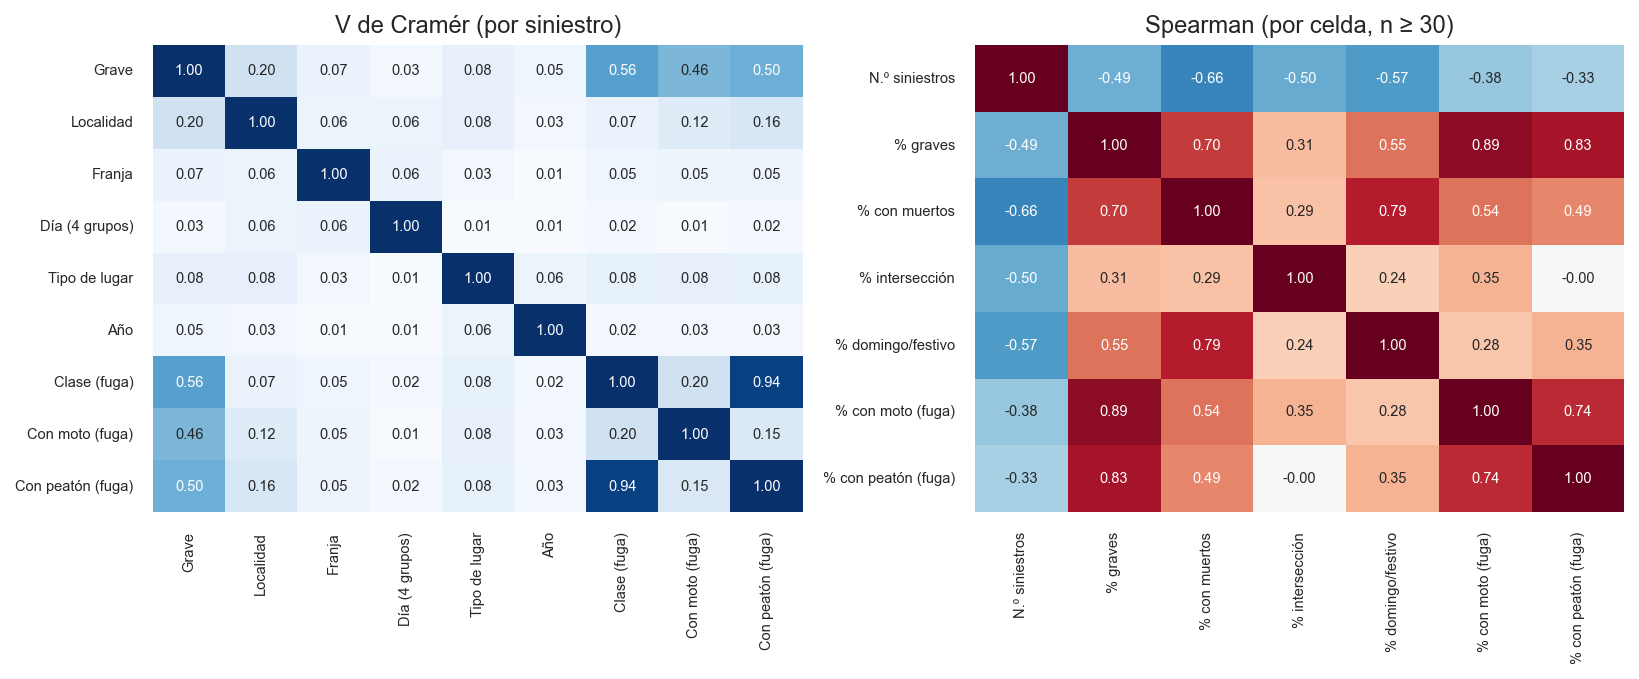

V de Cramér con Grave: {'Localidad': 0.2, 'Franja': 0.07, 'Día (4 grupos)': 0.03, 'Tipo de lugar': 0.08, 'Año': 0.05, 'Clase (fuga)': 0.56, 'Con moto (fuga)': 0.46, 'Con peatón (fuga)': 0.5}


In [10]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

vars_cat = {'Grave': base.grave, 'Localidad': base.localidad, 'Franja': base.franja.astype(str), 'Día (4 grupos)': base.dia4,
            'Tipo de lugar': base.tipo_lugar, 'Año': base.anio, 'Clase (fuga)': base.clase,
            'Con moto (fuga)': base.con_moto, 'Con peatón (fuga)': base.con_peaton}
nombres_v = list(vars_cat)
V = pd.DataFrame(np.eye(len(nombres_v)), index=nombres_v, columns=nombres_v)
for i, a in enumerate(nombres_v):
    for b in nombres_v[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = v_cramer(vars_cat[a], vars_cat[b])

aux = base.assign(es_interseccion=(base.tipo_lugar == 'Intersección').astype(int),
                  es_domingo=(base.dia4 == 'Domingo o festivo').astype(int))
pc = aux.groupby(['localidad', 'franja'], observed=True).agg(
    **{'N.º siniestros': ('grave', 'size'), '% graves': ('grave', 'mean'), '% con muertos': ('con_muertos', 'mean'),
       '% intersección': ('es_interseccion', 'mean'), '% domingo/festivo': ('es_domingo', 'mean'),
       '% con moto (fuga)': ('con_moto', 'mean'), '% con peatón (fuga)': ('con_peaton', 'mean')})
S = pc[pc['N.º siniestros'] >= 30].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sns.heatmap(V, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar=False, annot_kws={'size': 7})
axes[0].set_title('V de Cramér (por siniestro)')
sns.heatmap(S, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[1], cbar=False, annot_kws={'size': 7})
axes[1].set_title('Spearman (por celda, n ≥ 30)')
for a in axes: a.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig('figs/fig4_correlaciones.pdf'); plt.show()
print('V de Cramér con Grave:', V['Grave'].drop('Grave').round(2).to_dict())

**Qué vemos.** Lo que más se asocia con la gravedad son las variables de fuga (clase del siniestro, moto, peatón): confirma por qué no pueden entrar al modelo. Entre las que sí se conocen antes, la localidad es la que más se asocia (alrededor de 0,20); franja, tipo de lugar y día mucho menos. Es normal: el modelo no busca adivinar si *un* siniestro será grave, sino estimar la proporción de graves de cada zona y hora.

### 3.8 ¿Ordenar por número de graves y por proporción de graves da lo mismo?
La comparación central del proyecto: el criterio actual (cuántos graves se acumulan) frente al propuesto (qué parte es grave).

In [11]:
c = celdas[celdas.n >= 30].copy()
c['puesto_conteo'] = c.graves.rank(ascending=False, method='min').astype(int)
c['puesto_proporcion'] = c.prop.rank(ascending=False, method='min').astype(int)
top_prop = c.nsmallest(10, 'puesto_proporcion')
print('Celdas del top 10 por proporción que están en el top 10 por conteo:', (top_prop.puesto_conteo <= 10).sum())
print('Mejor puesto por conteo dentro del top 10 por proporción:', top_prop.puesto_conteo.min())
print('De esas 10, cuántas son de noche:', top_prop.franja.astype(str).str.startswith('Noche').sum())
display(top_prop[['localidad', 'franja', 'n', 'graves', 'prop', 'puesto_conteo']])

Celdas del top 10 por proporción que están en el top 10 por conteo: 0
Mejor puesto por conteo dentro del top 10 por proporción: 19
De esas 10, cuántas son de noche: 6


,localidad,franja,n,graves,prop,puesto_conteo
49,San Cristóbal,Mañana (6-12),1537,845,0.550,27
47,Rafael Uribe Uribe,Noche (18-24),1146,623,0.544,43
51,San Cristóbal,Noche (18-24),1235,665,0.538,40
79,Usme,Noche (18-24),898,480,0.535,55
45,Rafael Uribe Uribe,Mañana (6-12),1331,695,0.522,38
46,Rafael Uribe Uribe,Tarde (12-18),1497,754,0.504,34
50,San Cristóbal,Tarde (12-18),1539,775,0.504,33
3,Antonio Nariño,Noche (18-24),859,432,0.503,57
19,Ciudad Bolívar,Noche (18-24),1717,859,0.500,25
11,Bosa,Noche (18-24),2167,1074,0.496,19


**Qué vemos.** Ninguna de las 10 celdas con mayor proporción de graves está entre las 10 con más siniestros graves; la mejor ubicada por conteo es Bosa de noche, en el puesto 19. Las 10 son de localidades del sur y 6 de ellas son de noche. Si la Secretaría ordena solo por conteo, estas zonas y horas no aparecen arriba. Cuáles de estas diferencias son seguras y cuáles azar es lo que responde el modelo.

### 3.9 Tablas para el documento

In [12]:
def tabla_latex(df, columnas, encabezados, caption, label, ruta, primera='{}'):
    filas = ['\\begin{table}[h]\\centering\\small', f'\\caption{{{caption}}}\\label{{{label}}}',
             '\\begin{tabular}{l' + 'r' * len(columnas) + '}', '\\toprule', ' & '.join(encabezados) + ' \\\\', '\\midrule']
    for idx, f in df.iterrows():
        valores = [f'{f[col]:,.0f}'.replace(',', '.') if 'pct' not in col else f'{f[col]:.1f}'.replace('.', ',') for col in columnas]
        filas.append(f'{idx} & ' + ' & '.join(valores) + ' \\\\')
    filas += ['\\bottomrule', '\\end{tabular}', '\\end{table}']
    open(ruta, 'w', encoding='utf-8').write('\n'.join(filas))

enc = ['Siniestros', 'Graves', '\\% graves']
tabla_latex(franja_tab, ['siniestros', 'graves', 'pct_graves'], ['Franja'] + enc, 'Siniestros y proporción de graves por franja horaria, 2015--2019.', 'tab:franja', 'tablas/tab_franja.tex')
tabla_latex(loc, ['siniestros', 'graves', 'pct_graves'], ['Localidad'] + enc, 'Siniestros y proporción de graves por localidad, 2015--2019.', 'tab:localidad', 'tablas/tab_localidad.tex')
tabla_latex(por_anio, ['siniestros', 'graves', 'pct_graves'], ['Año'] + enc, 'Siniestros y proporción de graves por año.', 'tab:anio', 'tablas/tab_anio.tex')
tabla_latex(dia_tab, ['siniestros', 'graves', 'pct_graves'], ['Día'] + enc, 'Siniestros y proporción de graves por día, 2015--2019.', 'tab:dia', 'tablas/tab_dia.tex')
tabla_latex(lugar_tab, ['siniestros', 'graves', 'pct_graves'], ['Tipo de lugar'] + enc, 'Siniestros y proporción de graves por tipo de lugar, 2015--2019.', 'tab:lugar', 'tablas/tab_lugar.tex')
print(sorted(os.listdir('tablas')))

['tab_anio.tex', 'tab_dia.tex', 'tab_franja.tex', 'tab_localidad.tex', 'tab_lugar.tex']


## Figuras exploratorias del informe final (Figuras 1 a 4)
Mismo código que la sección 2 de `Grupo2_EntregaFinal_Bayesiana.py`.

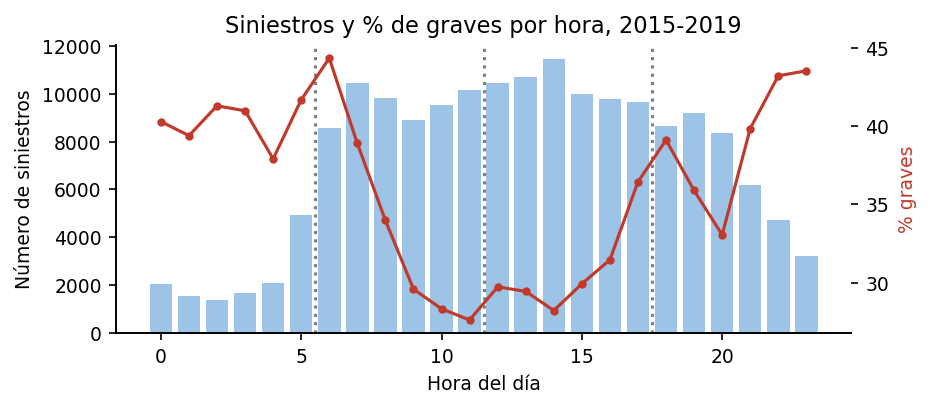

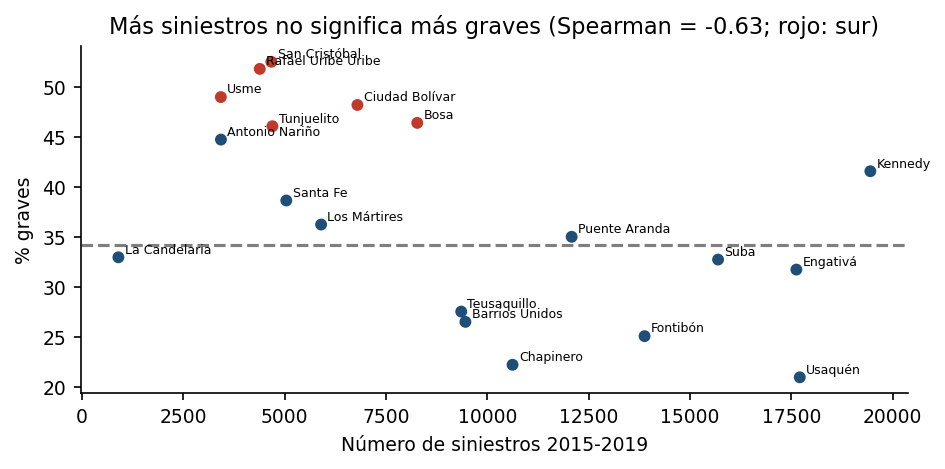

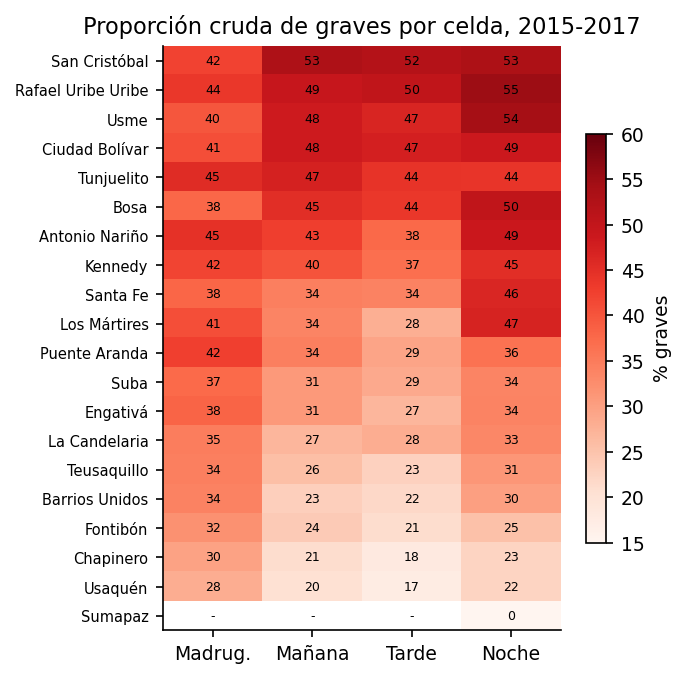

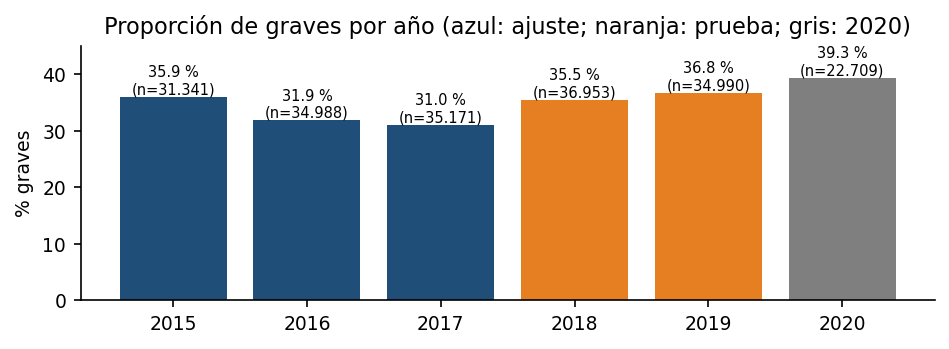

Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\02_eda.json


In [13]:
os.chdir(BASE)
# se quita el estilo de seaborn del EDA original para que las figuras sean idénticas a las del informe
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 150, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
R = {}
# ---------------------------------------------------------------------------
# 2. Figuras exploratorias (EDA)
# ---------------------------------------------------------------------------
base = df[df.anio <= 2019]
h = base.groupby("hora").grave.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.bar(h.index, h["size"], color="#9dc3e6")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Número de siniestros")
for x in (6, 12, 18):
    ax.axvline(x - 0.5, ls=":", color=GRIS)
ax2 = ax.twinx()
ax2.plot(h.index, 100 * h["mean"], color=ROJO, marker="o", ms=3)
ax2.set_ylabel("% graves", color=ROJO)
ax.set_title("Siniestros y % de graves por hora, 2015-2019")
fig.tight_layout()
fig.savefig(FIG / "eda_hora.png")
plt.show()

lo = base.groupby("localidad").grave.agg(["size", "mean"]).drop("Sumapaz")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.scatter(lo["size"], 100 * lo["mean"], c=[ROJO if i in SUR else AZUL for i in lo.index], s=22)
for nom, r in lo.iterrows():
    ax.annotate(nom, (r["size"], 100 * r["mean"]), fontsize=6, xytext=(3, 2), textcoords="offset points")
ax.axhline(100 * base.grave.mean(), ls="--", color=GRIS)
ax.set_xlabel("Número de siniestros 2015-2019")
ax.set_ylabel("% graves")
rho_loc = st.spearmanr(lo["size"], lo["mean"])[0]
ax.set_title(f"Más siniestros no significa más graves (Spearman = {rho_loc:.2f}; rojo: sur)")
fig.tight_layout()
fig.savefig(FIG / "eda_localidad.png")
plt.show()
R["eda_rho_localidad"] = float(rho_loc)

mat = (c_tr.y / c_tr.n.replace(0, np.nan)).values.reshape(L, F)
orden_loc = np.argsort(-np.nanmean(mat, axis=1))
fig, ax = plt.subplots(figsize=(4.6, 4.6))
im = ax.imshow(100 * mat[orden_loc], cmap="Reds", aspect="auto", vmin=15, vmax=60)
ax.set_xticks(range(F), ["Madrug.", "Mañana", "Tarde", "Noche"])
ax.set_yticks(range(L), [LOCS[i] for i in orden_loc], fontsize=7)
for i, li in enumerate(orden_loc):
    for j in range(F):
        v = mat[li, j]
        ax.text(j, i, "-" if np.isnan(v) else f"{100 * v:.0f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, label="% graves", shrink=0.7)
ax.set_title("Proporción cruda de graves por celda, 2015-2017")
fig.tight_layout()
fig.savefig(FIG / "eda_celdas.png")
plt.show()

an = df.groupby("anio").grave.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(6.4, 2.4))
cols = [AZUL] * 3 + [NARANJA] * 2 + [GRIS]
ax.bar(an.index, 100 * an["mean"], color=cols)
for x, v, n in zip(an.index, an["mean"], an["size"]):
    ax.text(x, 100 * v + 0.5, f"{100 * v:.1f} %\n(n={n:,})".replace(",", "."), ha="center", fontsize=7)
ax.set_ylim(0, 45)
ax.set_ylabel("% graves")
ax.set_title("Proporción de graves por año (azul: ajuste; naranja: prueba; gris: 2020)")
fig.tight_layout()
fig.savefig(FIG / "eda_anio.png")
plt.show()
R["eda_anio"] = {int(k): float(v) for k, v in an["mean"].items()}
guardar_json(R, '02_eda.json')